# Machine Learning Cross-Sectional para Seleção de Ações na B3 (IBrX 50)

**Autor:** Pedro Magalhães  
**Universo:** 41 Ações de Alta Liquidez da B3 (IBrX 50, 2012–2025)  
**Modelos Avaliados:** Regressão Linear com Regularização $L_2$ (**Ridge Baseline**), **XGBoost** (*depth-wise boosting*) e **LightGBM** (*leaf-wise boosting*)  
**Metodologia:** Engenharia de Atributos Causal ($\le t$) · Padronização *Cross-Sectional* por Pregão · Divisão Cronológica 70/20/10 com Purga (*Embargo* de 21 dias)

---

## 1. Visão Geral do Pipeline de Machine Learning
Este projeto implementa um pipeline quantitativo de Ciência de Dados para previsão do excesso de retorno de ações em 21 pregões:
1. **Higienização de Dados:** Remoção de feriados espúrios e mascaramento de períodos pré-listagem sem liquidez real.
2. **Engenharia de Features Causal ($\le t$):** 12 variáveis de momentum, volatilidade, reversão e volume padronizadas por *Z-score cross-sectional* a cada pregão.
3. **Divisão Temporal 70/20/10 com Purga:** Embargo de 21 pregões nas fronteiras para eliminar qualquer vazamento do retorno futuro.
4. **Treinamento e Otimização:** Seleção de hiperparâmetros na validação (20%) via *Rank IC*.
5. **Avaliação Multi-Métrica:** Regressão ($RMSE$, $MAE$, $R^2$), Ranking (*Pearson IC*, *Spearman Rank IC*), Classificação (*Acurácia Direcional*, $AUC	ext{-}ROC$, $F1$) e Desempenho de Seleção (Top 10 vs. *Buy & Hold* do Universo).

In [1]:
import sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT_DIR / "src"))

figures_dir = ROOT_DIR / "outputs" / "figures"
tables_dir = ROOT_DIR / "outputs" / "tables"

from quant_ml_b3 import (
    FEATURE_COLS,
    load_local_market_data,
    build_ml_panel,
    split_temporal_70_20_10,
)

market = load_local_market_data(ROOT_DIR / "data" / "processed")
print(f"Universo carregado: {len(market.tickers)} acoes x {len(market.dates)} pregoes ({market.dates[0].date()} a {market.dates[-1].date()})")
print("Tickers:", ", ".join(market.tickers[:10]), f"... (+{len(market.tickers)-10} acoes)")

Universo carregado: 41 acoes x 3630 pregoes (2012-01-02 a 2026-09-04)
Tickers: VALE3, ITUB4, PETR4, PETR3, BBDC4, SBSP3, B3SA3, ITSA4, WEGE3, ABEV3 ... (+31 acoes)


## 2. Divisão Cronológica com Purga (70% Treino / 20% Validação / 10% Teste)
Como o target preditivo mede o excesso de retorno nos 21 pregões seguintes ($t 	o t+21$), aplica-se uma zona de **purga (embargo de 21 dias)** antes da Validação e antes do Teste para evitar vazamento temporal.

In [2]:
market_15_25 = market.slice_dates("2015-01-02", "2025-12-31")
panel = build_ml_panel(market_15_25, horizon=21, step=5)
splits = split_temporal_70_20_10(panel, train_ratio=0.70, val_ratio=0.20, purge_days=21)

summary_splits = pd.DataFrame([
    {"Particao": "1. Treino (70%)", "Inicio": splits.meta["train_period"][0].date(), "Fim": splits.meta["train_period"][1].date(), "Datas": splits.meta["n_dates_train"], "Amostras (Data x Acao)": len(splits.train)},
    {"Particao": "2. Validacao (20% - Purga 21d)", "Inicio": splits.meta["val_period"][0].date(), "Fim": splits.meta["val_period"][1].date(), "Datas": splits.meta["n_dates_val"], "Amostras (Data x Acao)": len(splits.val)},
    {"Particao": "3. Teste Puro (10% - Purga 21d)", "Inicio": splits.meta["test_period"][0].date(), "Fim": splits.meta["test_period"][1].date(), "Datas": splits.meta["n_dates_test"], "Amostras (Data x Acao)": len(splits.test)},
])
display(summary_splits)

,Particao,Inicio,Fim,Datas,Amostras (Data x Acao)
0,1. Treino (70%),2015-04-07,2022-08-23,366,13265
1,2. Validacao (20% - Purga 21d),2022-09-28,2024-10-04,102,4063
2,3. Teste Puro (10% - Purga 21d),2024-11-08,2025-11-26,53,2171


## 3. Avaliação Estatística de Machine Learning (70 / 20 / 10)
Métricas consolidadas de Regressão, Ranking (*Information Coefficient*) e Classificação Direcional:

,Modelo,Particao,n_obs,RMSE,MAE,R2_pct,IC_Pearson,Rank_IC_Spearman,Acuracia_Direcional_pct,AUC_ROC,F1_Score,Spread_Top10_bps,Win_Periodos_Top10_pct
0,RIDGE,1. Treino (70%),13265,0.0989,0.0693,1.09,0.1045,0.0582,52.83,0.5316,0.4657,154.8,61.2
1,RIDGE,2. Validacao (20%),4063,0.0799,0.0582,-2.98,-0.0574,-0.0470,48.14,0.4820,0.4410,-50.2,39.2
2,RIDGE,3. Teste (10%),2171,0.0883,0.0634,-2.10,-0.0348,-0.0175,47.95,0.4861,0.4350,-9.8,50.9
3,XGBOOST,1. Treino (70%),13265,0.0980,0.0688,2.95,0.1908,0.1047,54.55,0.5547,0.4545,202.1,66.7
4,XGBOOST,2. Validacao (20%),4063,0.0798,0.0580,-2.60,-0.0138,-0.0182,50.14,0.4973,0.4185,-16.3,41.2
5,XGBOOST,3. Teste (10%),2171,0.0886,0.0638,-2.77,-0.0389,-0.0220,46.71,0.4866,0.3783,-57.0,49.1
6,LIGHTGBM,1. Treino (70%),13265,0.0955,0.0674,7.71,0.3412,0.2166,57.69,0.6028,0.4901,340.3,80.1
7,LIGHTGBM,2. Validacao (20%),4063,0.0800,0.0582,-3.28,0.0004,-0.0099,49.94,0.4985,0.4162,-11.9,46.1
8,LIGHTGBM,3. Teste (10%),2171,0.0890,0.0639,-3.87,-0.0267,-0.0052,48.13,0.5003,0.3953,-75.8,35.8


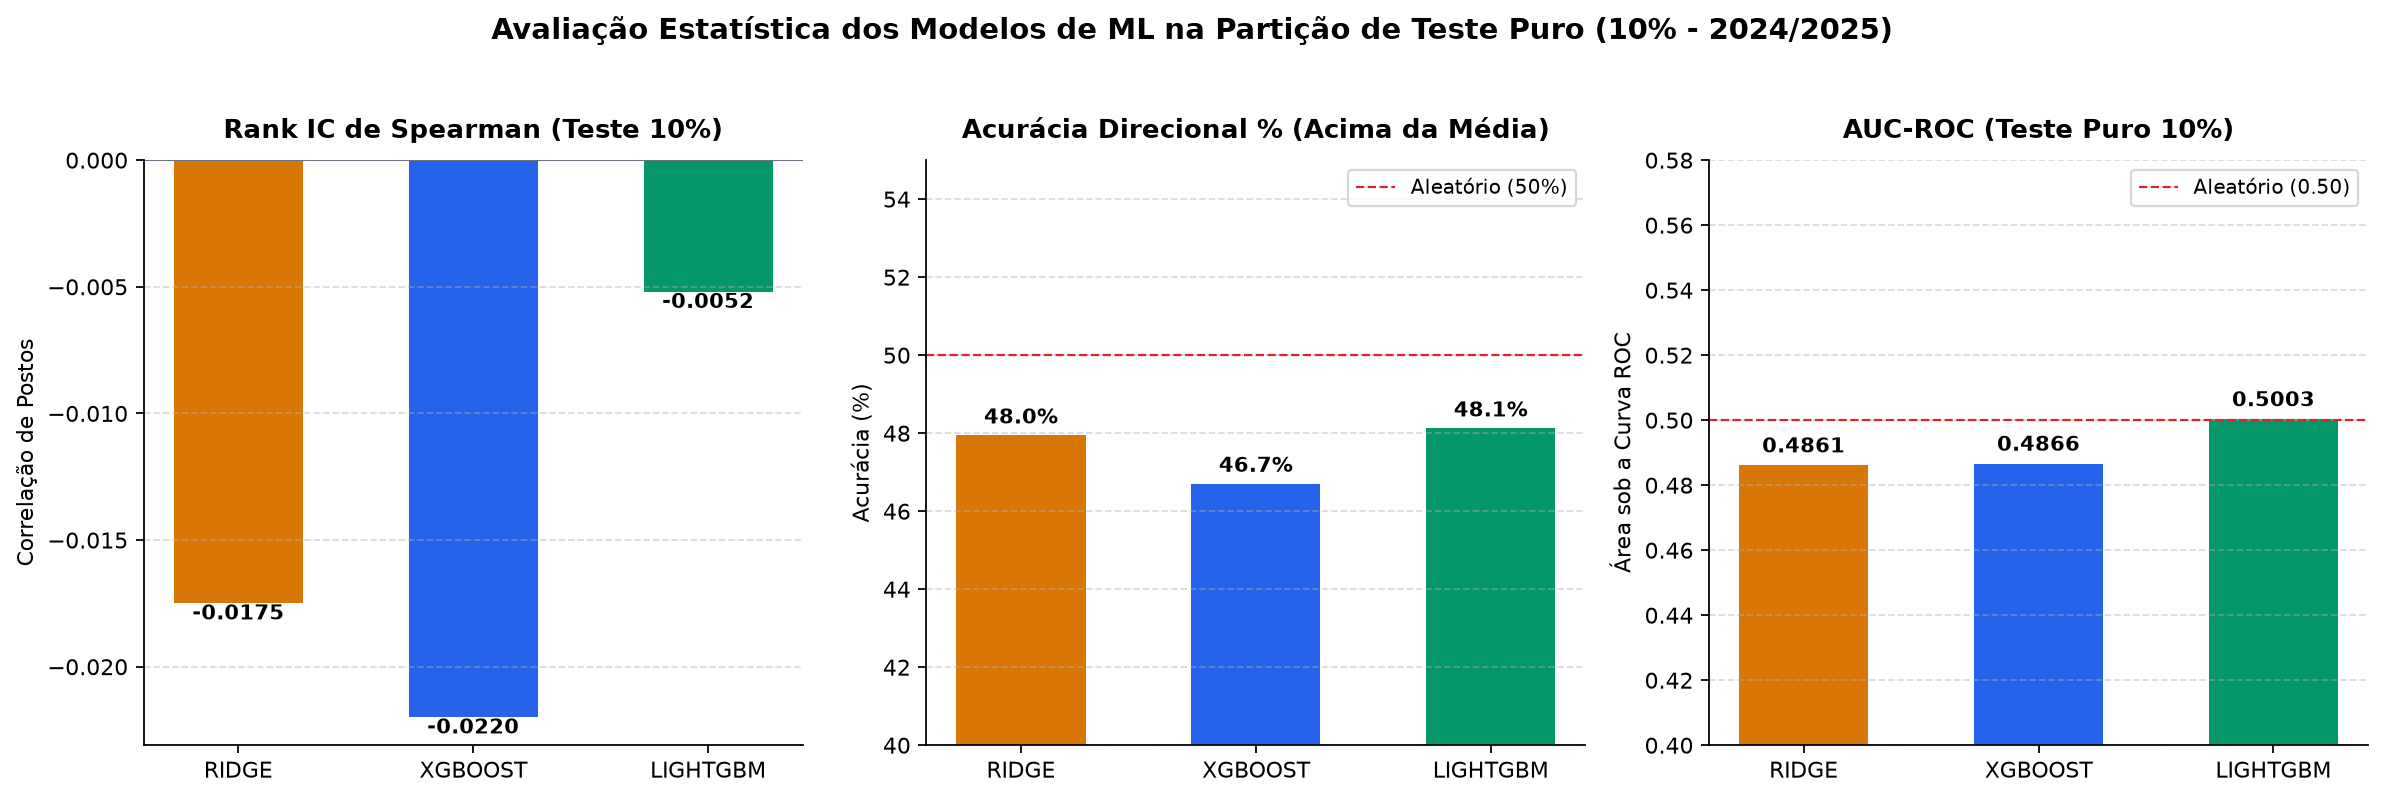

In [3]:
ml_metrics = pd.read_csv(ROOT_DIR / "outputs" / "tables" / "ml_metrics_70_20_10.csv")
display(ml_metrics)
display(Image(filename=str(ROOT_DIR / "outputs" / "figures" / "02_test_metrics_summary.png")))

## 4. Importância dos Atributos em Percentual de Ganho (Gain %)
Comparação entre o Ganho Relativo das árvores (**XGBoost** e **LightGBM**) e os coeficientes padronizados da **Regressão Ridge** ($L_2$):

,Feature,Ridge_Abs_Beta,Ridge_Beta,XGBoost_Gain,LightGBM_Gain
0,vol_21d,0.00887,0.00887,0.30606,0.16877
1,sma_ratio,0.00080,-0.00080,0.11784,0.12265
2,ret_63d,0.00060,-0.00060,0.11679,0.11057
3,ret_10d,0.00411,0.00411,0.09390,0.08160
4,ret_1d,0.00213,-0.00213,0.09329,0.08768
5,bb_pos,0.00527,-0.00527,0.07355,0.08550
6,sma50_dist,0.00028,-0.00028,0.07350,0.08078
7,ret_21d,0.00388,0.00388,0.04831,0.06676
8,vol_ratio,0.00016,0.00016,0.02861,0.06711
9,ret_5d,0.00222,0.00222,0.01680,0.04497


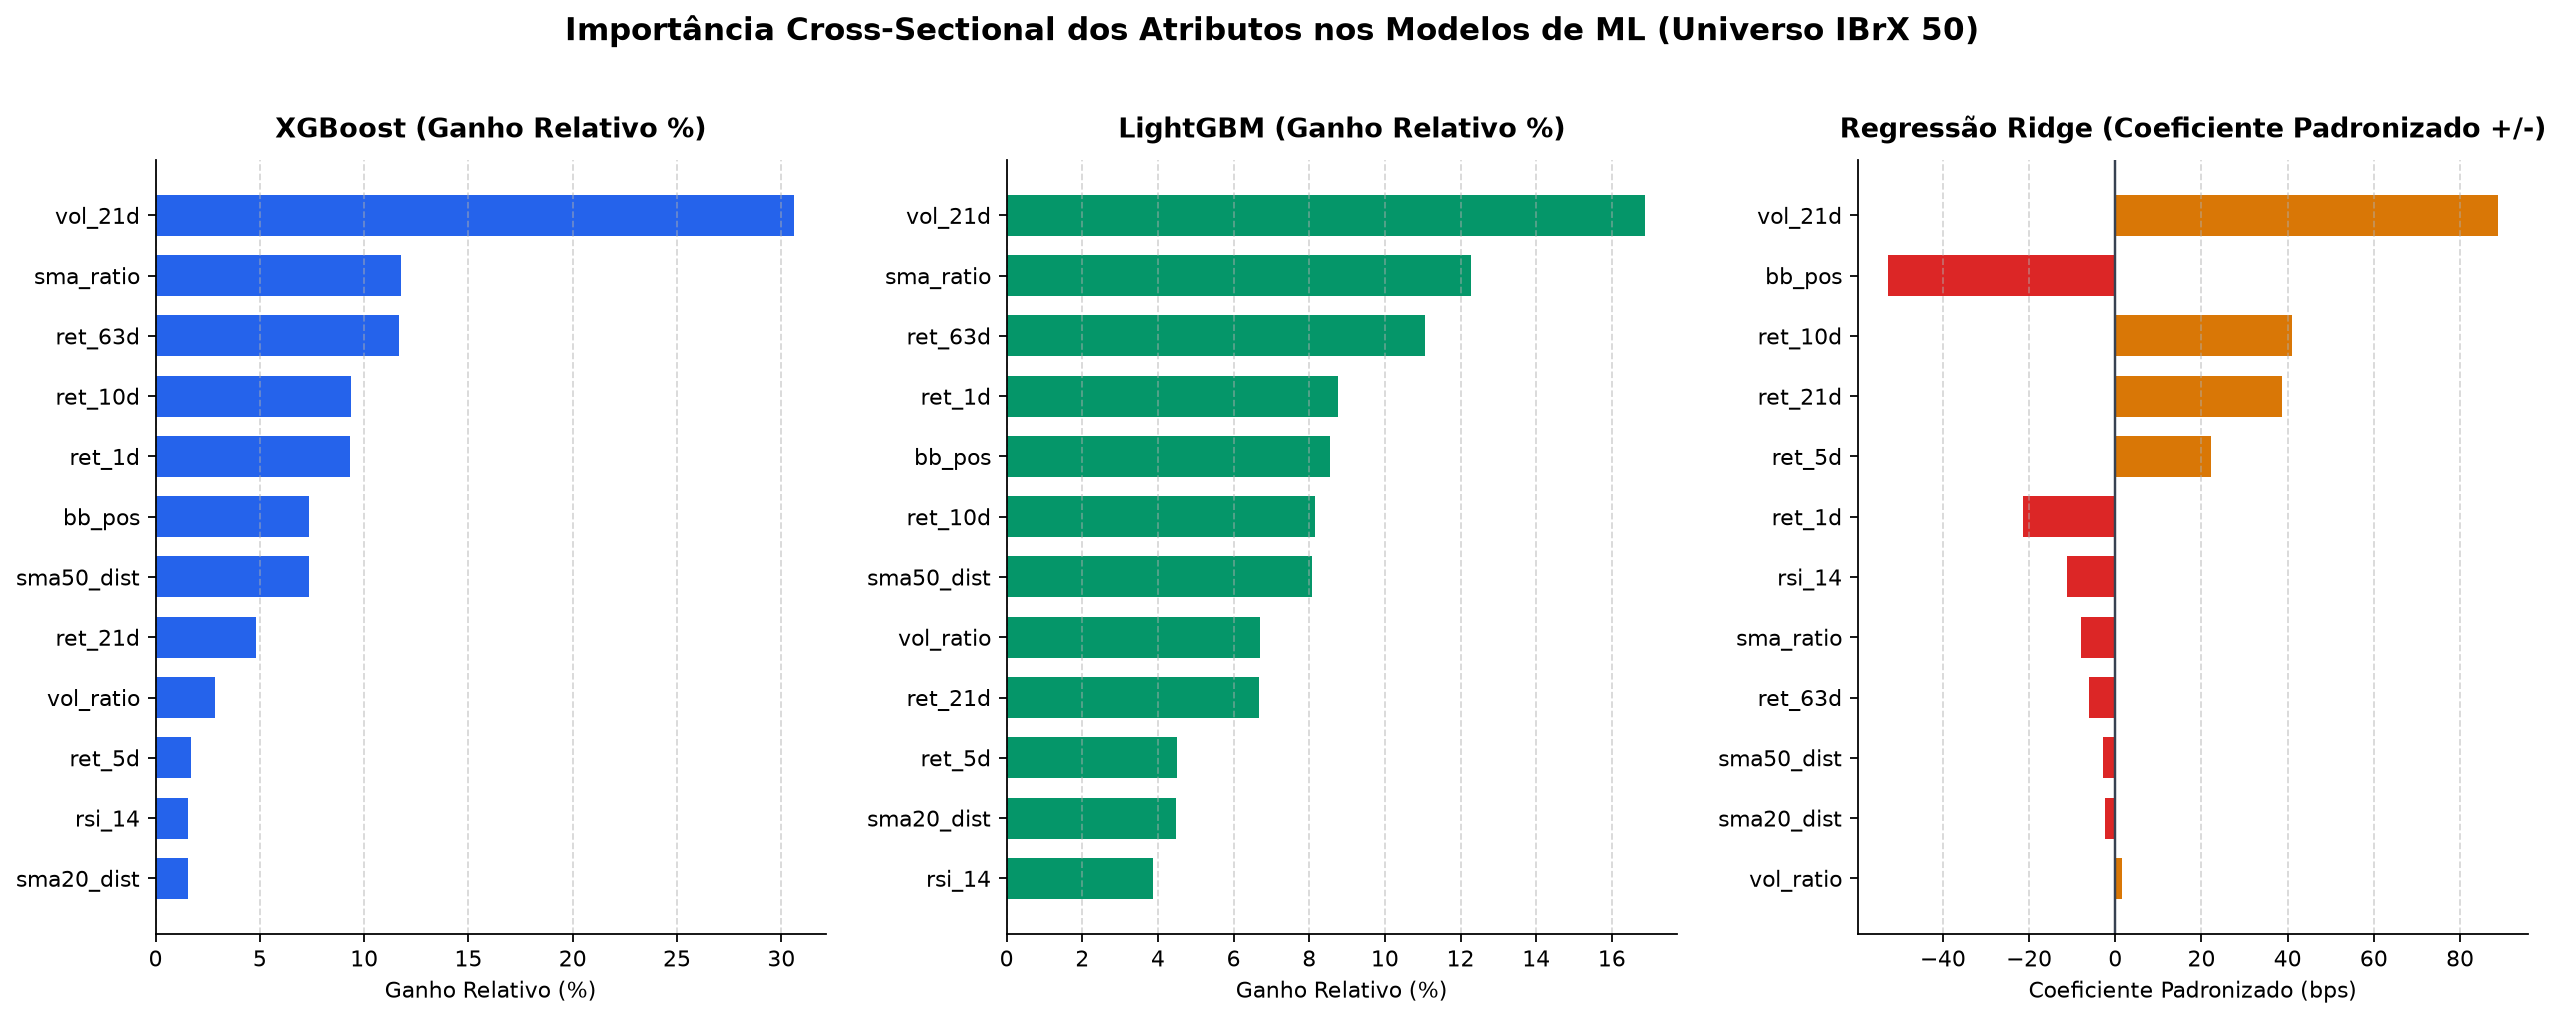

In [4]:
imp_df = pd.read_csv(ROOT_DIR / "outputs" / "tables" / "feature_importance.csv")
display(imp_df)
display(Image(filename=str(ROOT_DIR / "outputs" / "figures" / "01_feature_importance.png")))

## 5. Avaliação de Seleção de Portfólio (Top 10 vs. Buy & Hold do Universo)
Na partição de **Teste Puro (10% - nov/2024 a nov/2025)**, avaliamos o retorno acumulado composto ao selecionar as 10 ações com maior score predito a cada rebalanceamento contra a média igualitária do universo (*Buy & Hold*):

,Estrategia / Modelo,Retorno_Acumulado_pct,Alpha_vs_Mercado_pct
0,Buy & Hold (Universo 1/N),19.75,0.00
1,ML Baseline: Regressao Ridge,30.22,8.74
2,ML: XGBoost (Top 10),20.94,0.99
3,ML: LightGBM (Top 10),5.96,-11.52


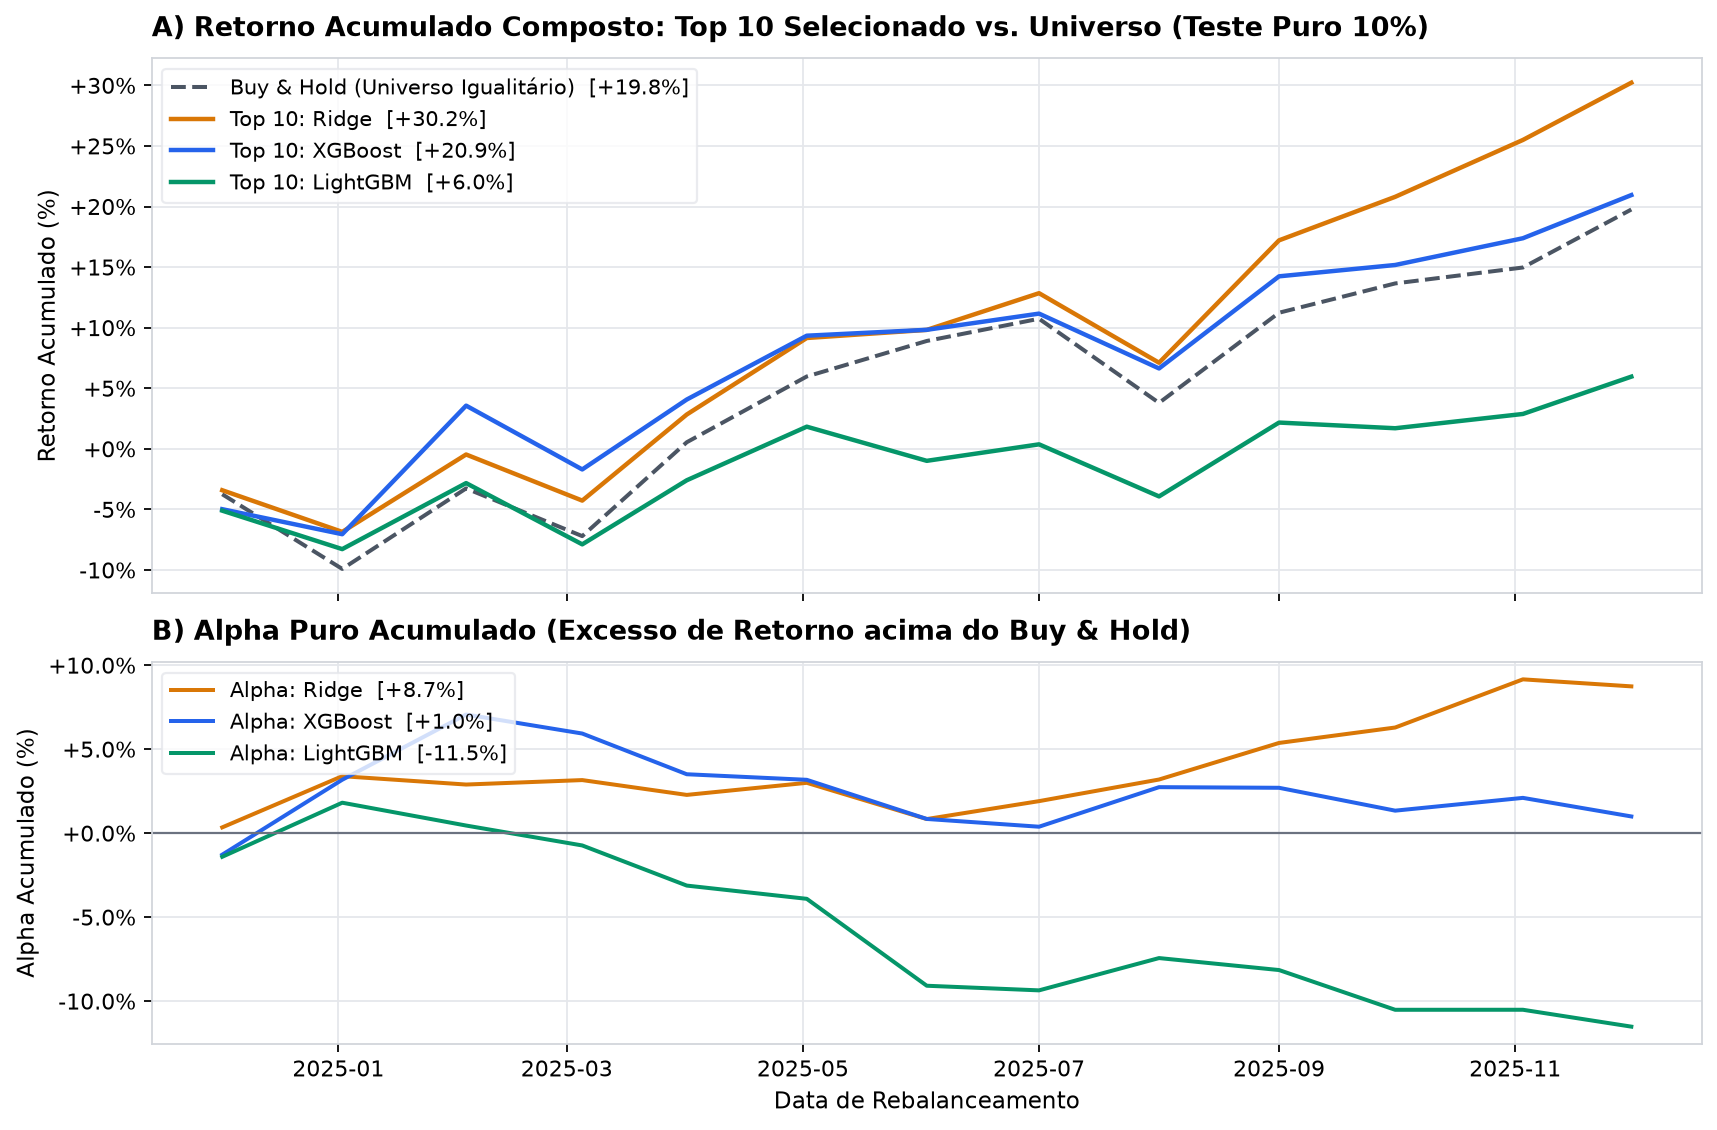

In [5]:
top10_perf = pd.read_csv(ROOT_DIR / "outputs" / "tables" / "top10_vs_universe_performance.csv")
display(top10_perf)
display(Image(filename=str(ROOT_DIR / "outputs" / "figures" / "03_top10_cumulative_alpha.png")))

## 6. Simulação Walk-Forward Multi-Ano: Retreino Periódico vs. Modelo Congelado (2015–2025)

Em finanças quantitativas, modelos preditivos enfrentam o fenômeno de **Concept Drift** (mudança de regime macroeconômico, ciclo da taxa Selic e choques inflacionários).

Abaixo comparamos o desempenho empírico ao longo de 11 anos de:
1. **Modelos Walk-Forward Dinâmicos**: Retreinados anualmente (a cada 12 meses com janela de 756 pregões e purga de 21 dias).
2. **Modelos Congelados (Static)**: Calibrados uma única vez no início (2012–2014) e operados sem qualquer atualização por 11 anos.
3. **Benchmark Passivo (Buy & Hold 1/N)**: Portfólio igualmente ponderado de todas as ações do universo.

,Estrategia,Modo,Retorno_Acumulado_pct,CAGR_pct,Volatilidade_Anualizada_pct,Sharpe_Ratio,Max_Drawdown_pct,Alpha_vs_Universo_pct,Ganho_Retreino_pct
0,Buy & Hold (Universo 1/N),Benchmark Passivo,615.00,19.74,24.26,0.81,-37.16,0.00,0.00
1,ML: RIDGE (Walk-Forward),Retreino a cada 12m,956.10,24.10,28.69,0.84,-40.35,4.36,4.73
2,ML: RIDGE (Congelado),Estatico (Sem Retreino),590.71,19.37,21.87,0.89,-36.71,-0.37,0.00
3,ML: XGBOOST (Walk-Forward),Retreino a cada 12m,1062.99,25.20,29.11,0.87,-37.39,5.46,6.27
4,ML: XGBOOST (Congelado),Estatico (Sem Retreino),563.51,18.93,23.59,0.80,-41.24,-0.81,0.00
5,ML: LIGHTGBM (Walk-Forward),Retreino a cada 12m,542.53,18.58,29.21,0.64,-42.62,-1.16,-4.06
6,ML: LIGHTGBM (Congelado),Estatico (Sem Retreino),828.28,22.64,22.75,1.00,-37.54,2.90,0.00


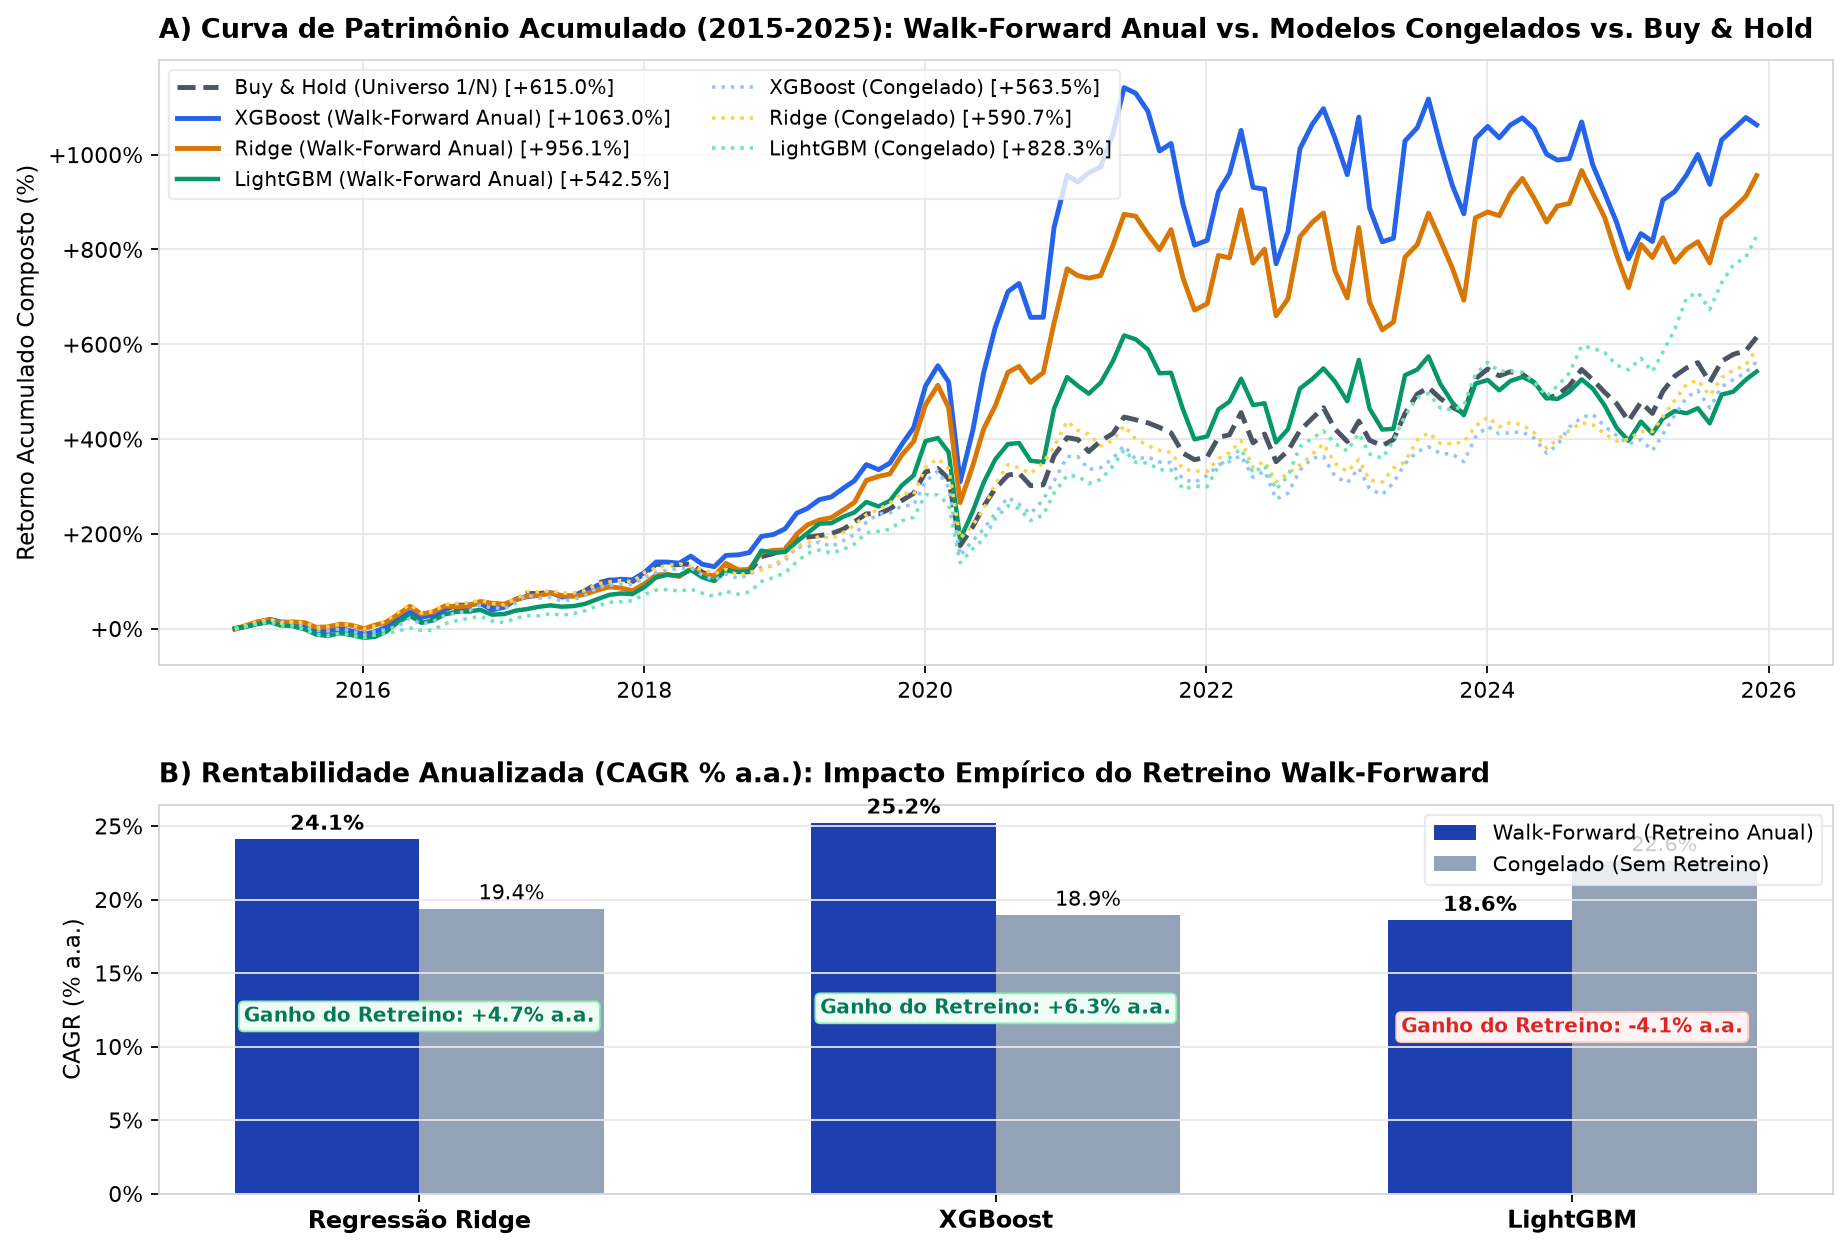

In [6]:
wf_comp = pd.read_csv(ROOT_DIR / 'outputs' / 'tables' / 'comparison_frozen_vs_walkforward.csv')
display(wf_comp)
display(Image(filename=str(ROOT_DIR / 'outputs' / 'figures' / '04_walkforward_vs_frozen_comparison.png')))

## 7. Políticas de Construção de Portfólio: Hard Cut (Top 10 1/N) vs. Soft Weighting (Top 15 Rank Linear)

Comparamos lado a lado duas filosofias de alocação quantitativa ao longo de 11 anos de Walk-Forward:
1. **Hard Cut (Top 10 1/N com Margem de Tolerância (Filtro Anti-Giro)):** Alocação equiponderada tradicional com filtro buffer de manutenção.
2. **Soft Weighting (Top 15 Rank Linear):** Ponderação suave onde os pesos decrescem linearmente ($w_i \propto M - i + 1$), eliminando o efeito de falésia (*cliff edge*) e a sensibilidade a empates e sementes estocásticas.


In [ ]:
from quant_ml_b3 import run_weighting_schemes_comparison, plot_weighting_schemes_comparison

figures_dir = ROOT_DIR / "outputs" / "figures"
tables_dir = ROOT_DIR / "outputs" / "tables"

weight_res = run_weighting_schemes_comparison(
    market=market,
    start_date="2015-01-02",
    end_date="2025-12-31",
    models=("ridge", "xgboost", "lightgbm"),
    retrain_every_months=12,
    train_lookback_days=756,
    top_k_hard=10,
    hysteresis_buffer=20,
    top_k_soft=15,
    seed=42,
)

print(weight_res.summary_metrics.to_string(index=False))

out_fig_path = figures_dir / "05_weighting_schemes_comparison.png"
plot_weighting_schemes_comparison(
    weight_res.cumulative_returns,
    weight_res.summary_metrics,
    out_fig_path,
)
display(Image(filename=str(out_fig_path)))
